Table of Contents:


1- set up

2- load data



#1-Setup

In [28]:
# Import modules
import numpy as np  # Library for numerical computing and array operations
import pandas as pd  # Library for handling tabular data
import matplotlib.pyplot as plt  # Library for basic data visualization
import seaborn as sns  # Library for statistical data visualization
from sklearn.preprocessing import LabelEncoder  # Encoder for converting categorical variables to numeric labels
from sklearn.ensemble import RandomForestClassifier  # Random Forest classifier
from sklearn.model_selection import StratifiedKFold  # Class for stratified K-fold cross-validation
from sklearn.metrics import roc_auc_score  # Metric function for computing ROC AUC
from sklearn.model_selection import train_test_split # To split data we don't have test data in the folder (generate train/test) data
from sklearn.metrics import classification_report # to evlauete the model
from sklearn.metrics import confusion_matrix # to evaluate the model
from sklearn.linear_model import LogisticRegression # for baseline model
!pip install catboost

#2- Load Data

2.1 Connect with Google Drive

In [29]:
# If you work with Google Colaboratory, please run this as well.
from google.colab import drive
drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
%cd "/content/drive/MyDrive/me/CGICertficate/Session7/FinalAssignment"

/content/drive/MyDrive/me/CGICertficate/Session7/FinalAssignment


Run the cell below to check if the path is correctly set.

In [31]:
from pathlib import Path

PATH = Path.cwd() / "telecom"

client_file = PATH / "Client.csv"
record_file = PATH / "Record.csv"


# Check if path exists
if client_file.exists() and record_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


2.2 Load all data

In [32]:

PATH = Path.cwd() / "telecom"
client = pd.read_csv(client_file)
record = pd.read_csv(record_file)

print(f"Cleint: {client.shape}, Record: {record.shape}");

Cleint: (100000, 50), Record: (100000, 51)


2.3 We don't have test data so we nedd to read all heads for 2 files to decide next step


In [33]:
client.head()

,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,...,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,...,0.0,N,U,U,U,U,U,Y,361.0,1000001
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,...,0.0,Z,U,U,U,U,U,Y,240.0,1000002
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,...,0.0,N,U,Y,U,U,U,Y,1504.0,1000003
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,...,0.0,U,Y,U,U,U,U,Y,1812.0,1000004
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,...,0.0,I,U,U,U,U,U,Y,434.0,1000005


In [34]:
record.head()

,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,...,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,...,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,...,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,...,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,...,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005


There is a relation by Customer_Id so we will Merge 2 files by Customer_id , to have one file contains all data

In [35]:
customers_df = pd.merge(client, record, on='Customer_ID')

In [36]:
customers_df.shape

(100000, 100)

In [37]:
customers_df.head()

,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,...,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,...,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,...,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,...,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,...,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,...,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57


In [38]:
customers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 100 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   uniqsubs          100000 non-null  int64  
 1   actvsubs          100000 non-null  int64  
 2   new_cell          100000 non-null  object 
 3   crclscod          100000 non-null  object 
 4   asl_flag          100000 non-null  object 
 5   totcalls          100000 non-null  int64  
 6   totmou            100000 non-null  float64
 7   totrev            100000 non-null  float64
 8   adjrev            100000 non-null  float64
 9   adjmou            100000 non-null  float64
 10  adjqty            100000 non-null  int64  
 11  avgrev            100000 non-null  float64
 12  avgmou            100000 non-null  float64
 13  avgqty            100000 non-null  float64
 14  avg3mou           100000 non-null  int64  
 15  avg3qty           100000 non-null  int64  
 16  avg3rev           10

#3.Data Analysis & EDA

EDA (Exploratory Data Analysis) is an essential step for understanding the structure and characteristics of your data before building a model.

At this stage, you explore trends and patterns in the dataset, as well as outliers, missing values, and imbalanced distributions. For example, some variables may contain extreme values, or the data may be heavily skewed toward specific categories. Identifying these characteristics helps you find potential issues that could hurt performance and uncover features that may be useful for prediction.

By performing EDA, you can detect and address problems early—such as “training fails due to missing values” or “the model becomes unstable because of outliers.” This reduces rework later and enables more efficient preprocessing and feature engineering.

Insights from EDA also inform later decisions, including model selection and hyperparameter tuning. In machine learning competitions, EDA is often a key process for improving final scores.

3.1 count how many churn customers do we have

In [39]:
# Count + percentage
print(customers_df['churn'].value_counts())
print(customers_df['churn'].value_counts(normalize=True) * 100)

churn
0    50438
1    49562
Name: count, dtype: int64
churn
0    50.438
1    49.562
Name: proportion, dtype: float64


3.2 Checking Missing Values
First, let's check for missing values. This is an essential step in machine-learning-based data analysis, because most machine learning models cannot train on or make predictions from data that contains missing values, and will raise an error.

In [40]:
missing_values = customers_df.isnull().sum().sort_values(ascending=False)

missing_values[missing_values > 0]

,0
numbcars,49366
dwllsize,38308
HHstatin,37923
ownrent,33706
dwlltype,31909
lor,30190
income,25436
adults,23019
infobase,22079
hnd_webcap,10189


# 3.3 Visualization and Analysis

3.3.1 Missing Values Percentage

In [41]:
missing_percent = (customers_df.isnull().sum() / len(customers_df)) * 100
missing_percent = missing_percent.sort_values(ascending=False)

print(missing_percent[missing_percent > 0])

numbcars            49.366
dwllsize            38.308
HHstatin            37.923
ownrent             33.706
dwlltype            31.909
lor                 30.190
income              25.436
adults              23.019
infobase            22.079
hnd_webcap          10.189
prizm_social_one     7.388
avg6rev              2.839
avg6qty              2.839
avg6mou              2.839
ethnic               1.732
forgntvl             1.732
marital              1.732
kid0_2               1.732
rv                   1.732
truck                1.732
kid3_5               1.732
kid16_17             1.732
kid11_15             1.732
kid6_10              1.732
creditcd             1.732
change_rev           0.891
change_mou           0.891
hnd_price            0.847
rev_Mean             0.357
mou_Mean             0.357
da_Mean              0.357
ovrrev_Mean          0.357
totmrc_Mean          0.357
ovrmou_Mean          0.357
vceovr_Mean          0.357
roam_Mean            0.357
datovr_Mean          0.357
a

Now draw them:

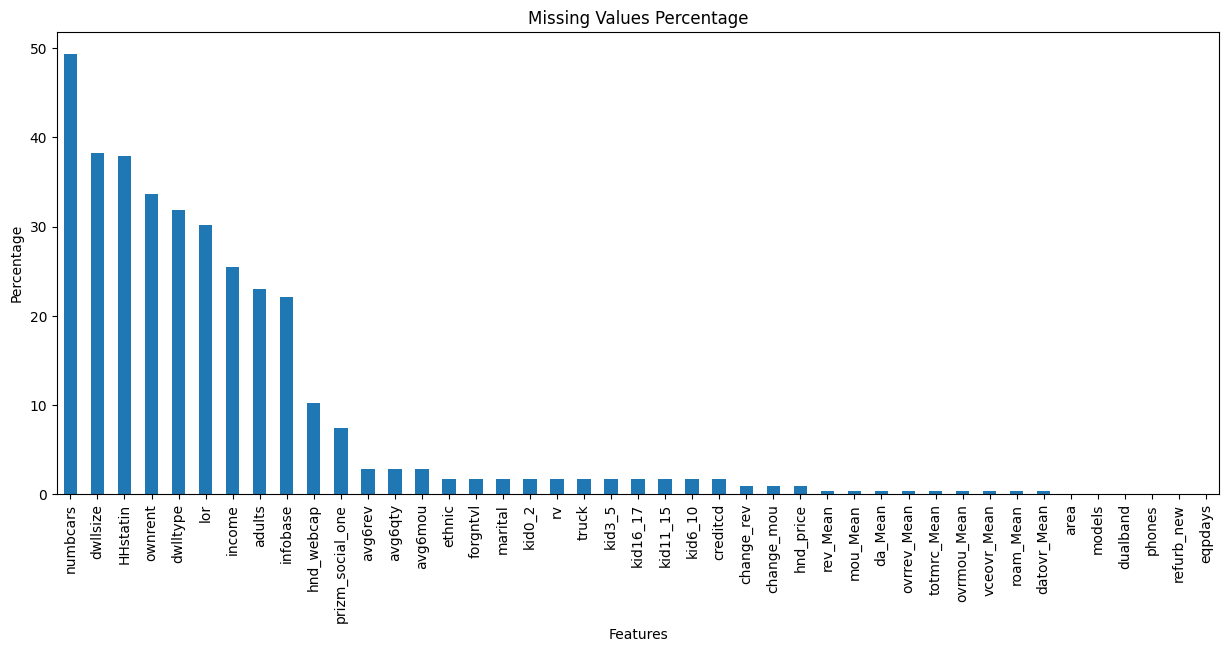

In [42]:
missing_percent[missing_percent > 0].plot(
    kind='bar',
    figsize=(15,6)
)

plt.title('Missing Values Percentage')
plt.ylabel('Percentage')
plt.xlabel('Features')
plt.xticks(rotation=90)
plt.show()

In [43]:
missing_percentage = (
    customers_df.isnull().mean() * 100
).sort_values(ascending=False)

missing_percentage.head(15)

,0
numbcars,49.366
dwllsize,38.308
HHstatin,37.923
ownrent,33.706
dwlltype,31.909
lor,30.190
income,25.436
adults,23.019
infobase,22.079
hnd_webcap,10.189


3.3.2 Analyze churn distribution visually

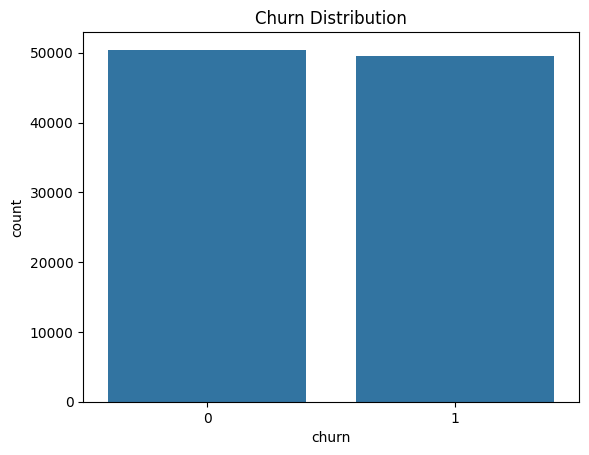

In [44]:
sns.countplot(x='churn', data=customers_df)

plt.title('Churn Distribution')
plt.show()

3.3.3 Important numerical features vs churn

First get numeric columns:

In [45]:
numeric_cols = customers_df.select_dtypes(include=['int64', 'float64']).columns

Now visualize correlation with churn:

In [46]:
correlation = customers_df[numeric_cols].corr()['churn'].sort_values(ascending=False)

print(correlation)

churn            1.000000
eqpdays          0.112691
uniqsubs         0.039882
vceovr_Mean      0.024240
ovrrev_Mean      0.023736
                   ...   
complete_Mean   -0.051740
mou_cvce_Mean   -0.052042
mou_Mean        -0.057027
totmrc_Mean     -0.068558
hnd_price       -0.103184
Name: churn, Length: 79, dtype: float64


Draw it

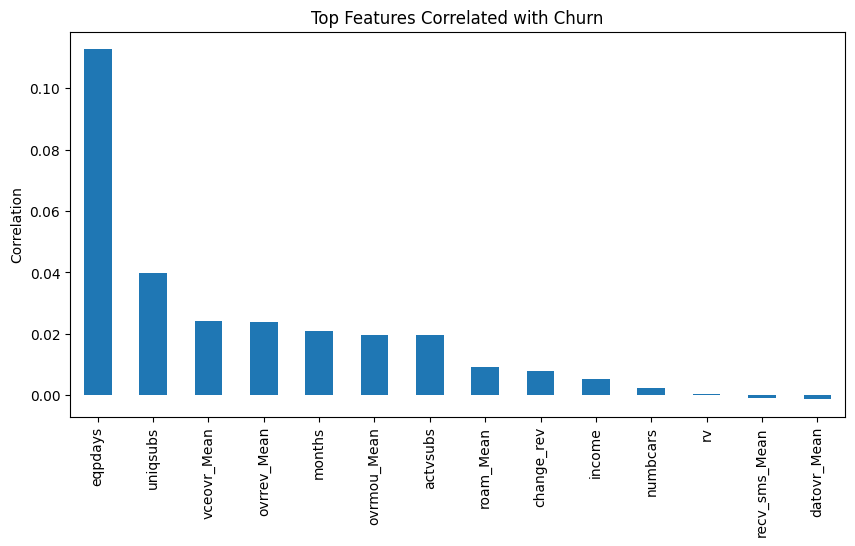

In [47]:
top_corr = correlation[1:15]

top_corr.plot(kind='bar', figsize=(10,5))

plt.title('Top Features Correlated with Churn')
plt.ylabel('Correlation')
plt.show()

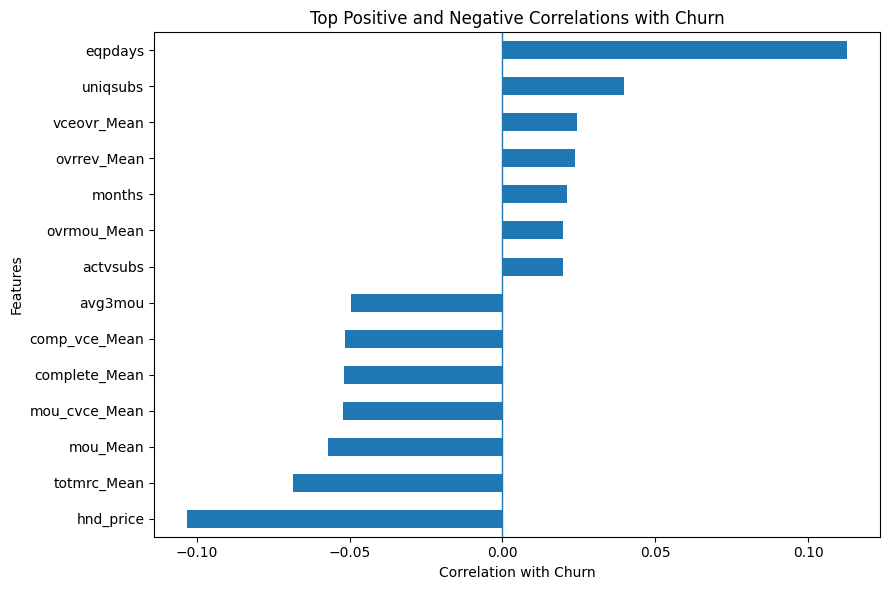

In [48]:
# Correlation with churn for numeric features only
correlation = customers_df.select_dtypes(include='number').corr()['churn'].drop('churn')

# Select strongest positive and strongest negative correlations
top_positive = correlation.sort_values(ascending=False).head(7)
top_negative = correlation.sort_values(ascending=True).head(7)

# Combine them
top_corr = pd.concat([top_positive, top_negative])

# Sort for better horizontal bar display
top_corr = top_corr.sort_values()

plt.figure(figsize=(9, 6))

top_corr.plot(kind='barh')

plt.title('Top Positive and Negative Correlations with Churn')
plt.xlabel('Correlation with Churn')
plt.ylabel('Features')

# Add vertical line at zero
plt.axvline(0, linewidth=1)

plt.tight_layout()
plt.show()

Exatracted all numeric values and draw them except customer_id and chrun



In [49]:
# Extraxt numeric columns (excluding the 'Id' and 'Drafted' columns)
numeric_cols = customers_df.select_dtypes(include=['number']).columns
numeric_cols = numeric_cols.drop(['Customer_ID', 'churn'])

# Plot
num_cols = len(numeric_cols)
cols = 3
rows = (num_cols + cols - 1) // cols

plt.figure(figsize=(5 * cols, 4 * rows))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(rows, cols, i)
    plt.hist(customers_df[col].dropna(), bins=30, edgecolor='black')
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

Let's examine the correlation matrix of the numerical features using a heatmap.

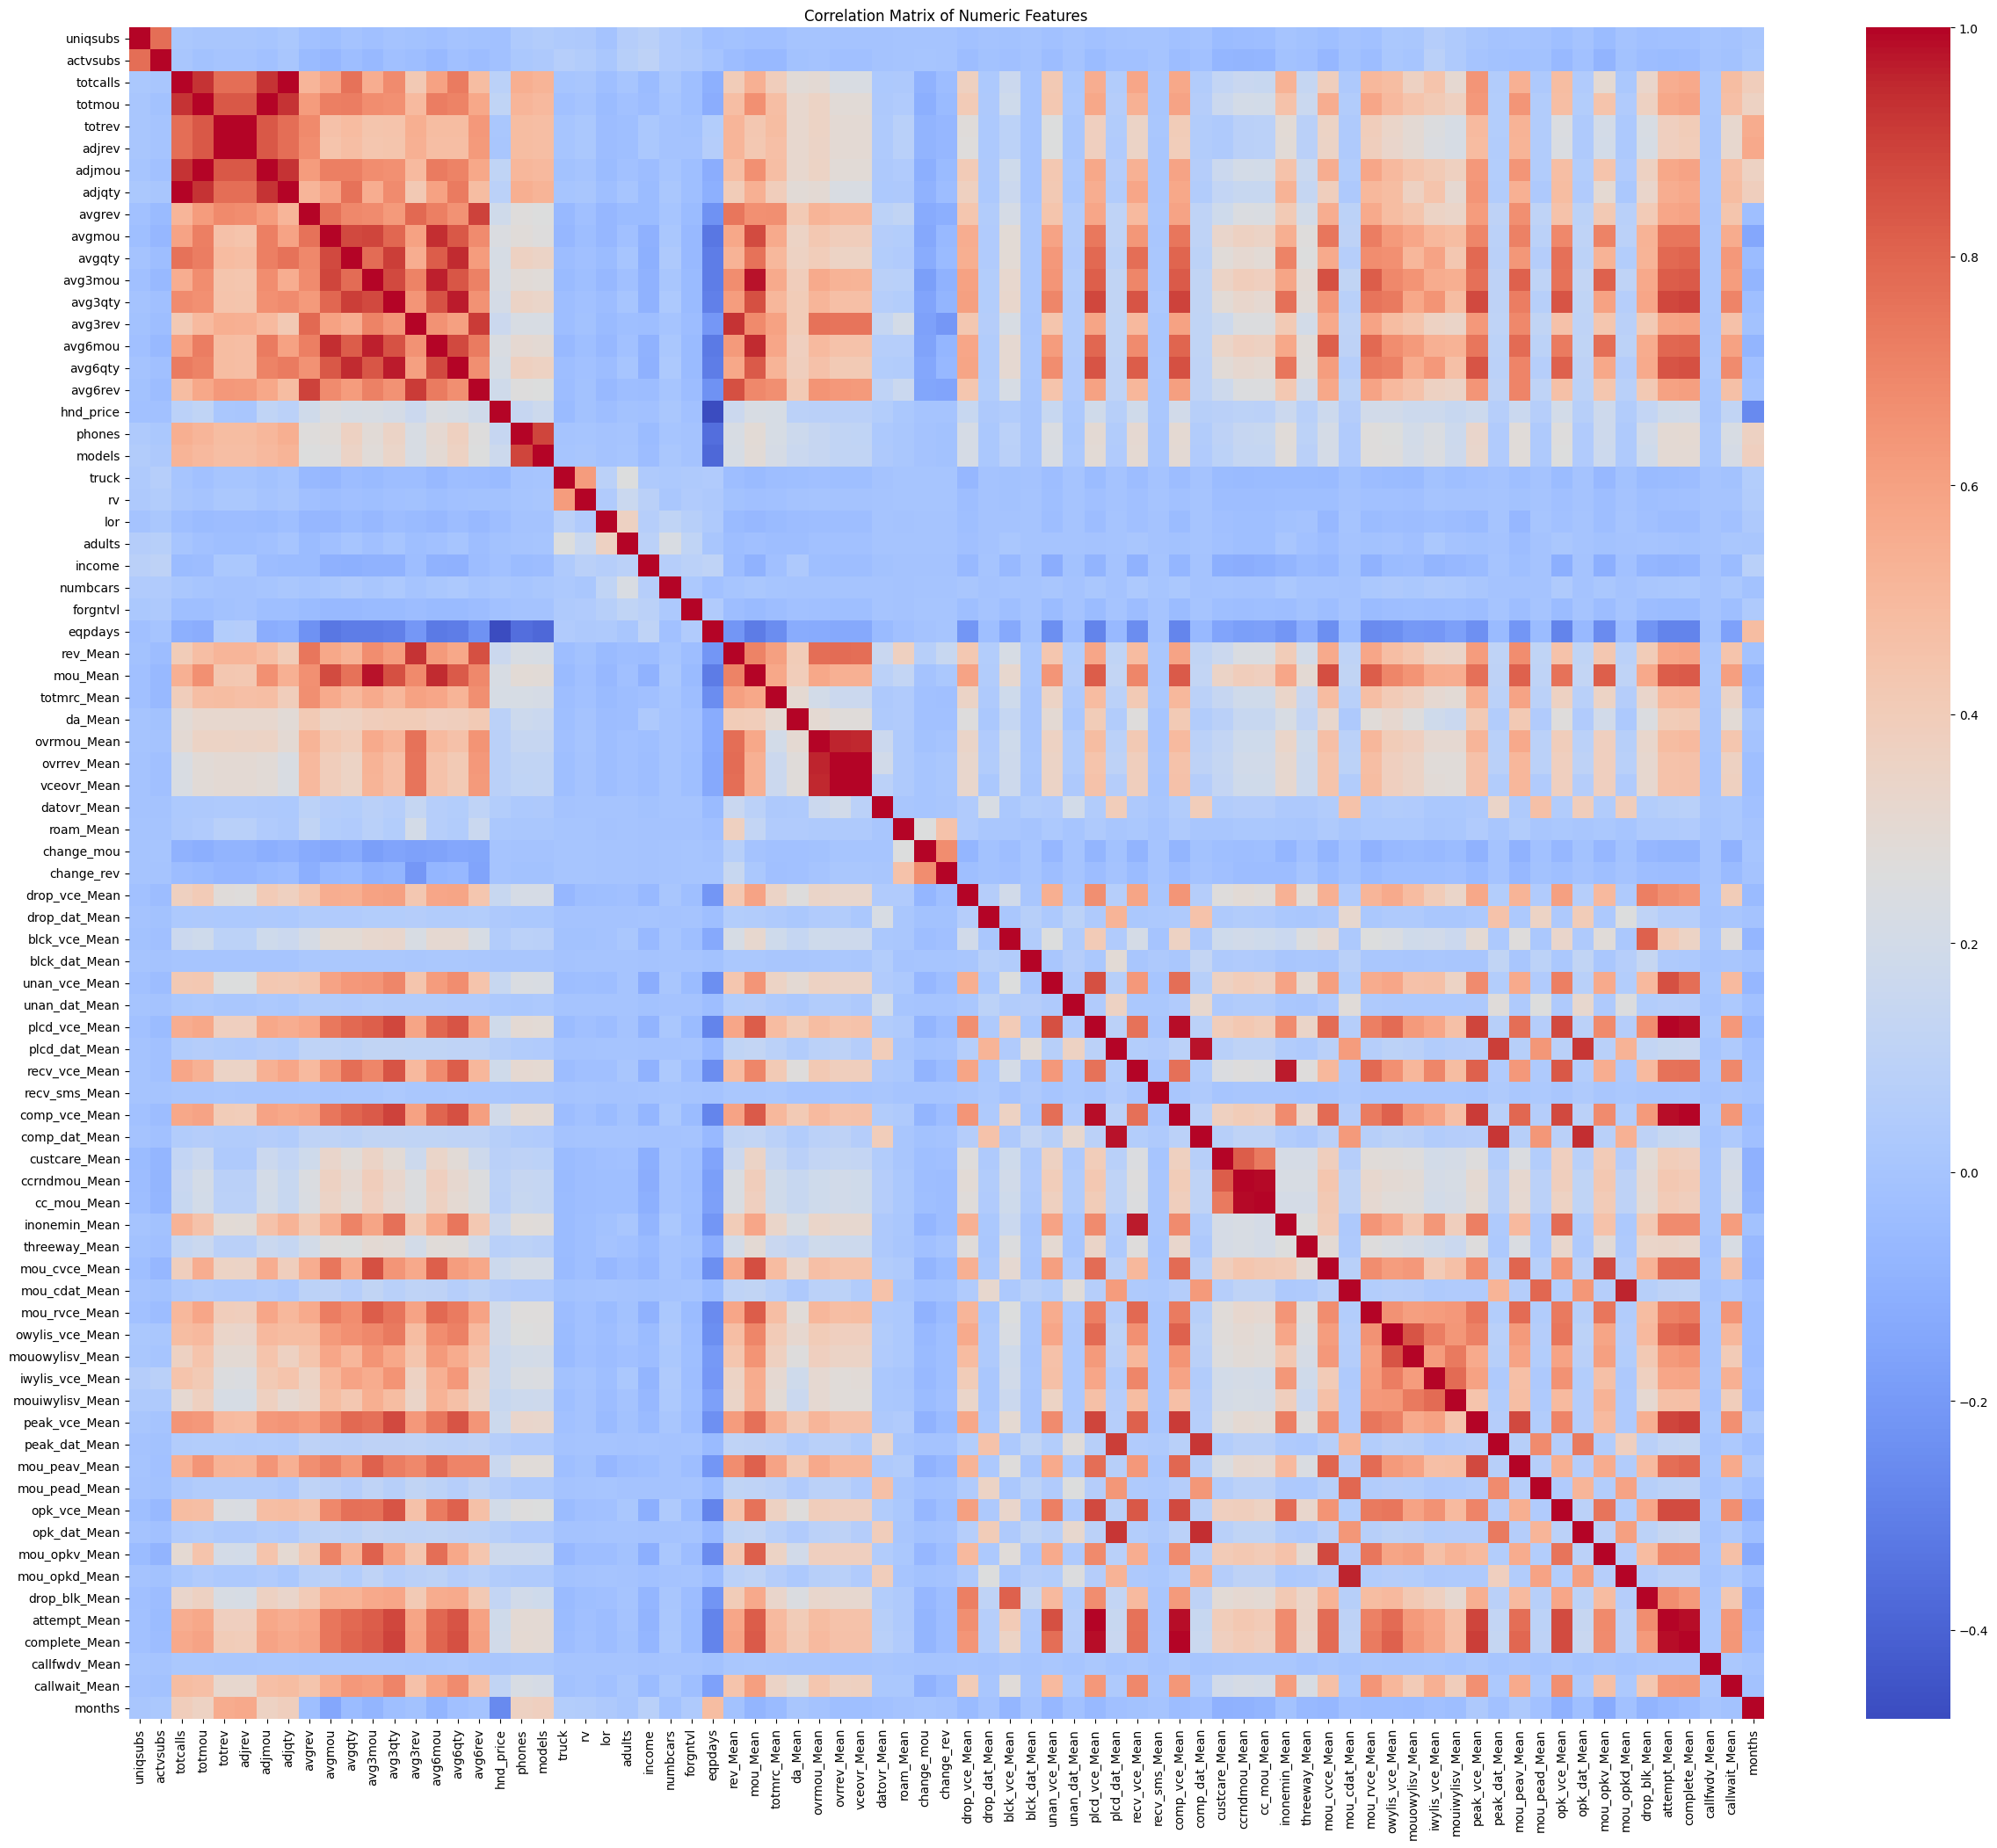

In [50]:
# Extract numeric columns (excluding the 'Id' and ''Drafted' columns)
numeric_cols = customers_df.select_dtypes(include=['number']).drop(['Customer_ID', 'churn'], axis=1)

# Compute the correlation matrix
corr_matrix = numeric_cols.corr()

# Plot a heatmap
plt.figure(figsize=(30, 25))
sns.heatmap(
    corr_matrix,
    annot=False,
    # fmt='.2f',
    cmap='coolwarm',
    # vmin=-1, vmax=1,
    # square=True,
    # linewidths=2
)
#   Note---------  commented values for better view

plt.title('Correlation Matrix of Numeric Features', fontsize=12)
plt.show()

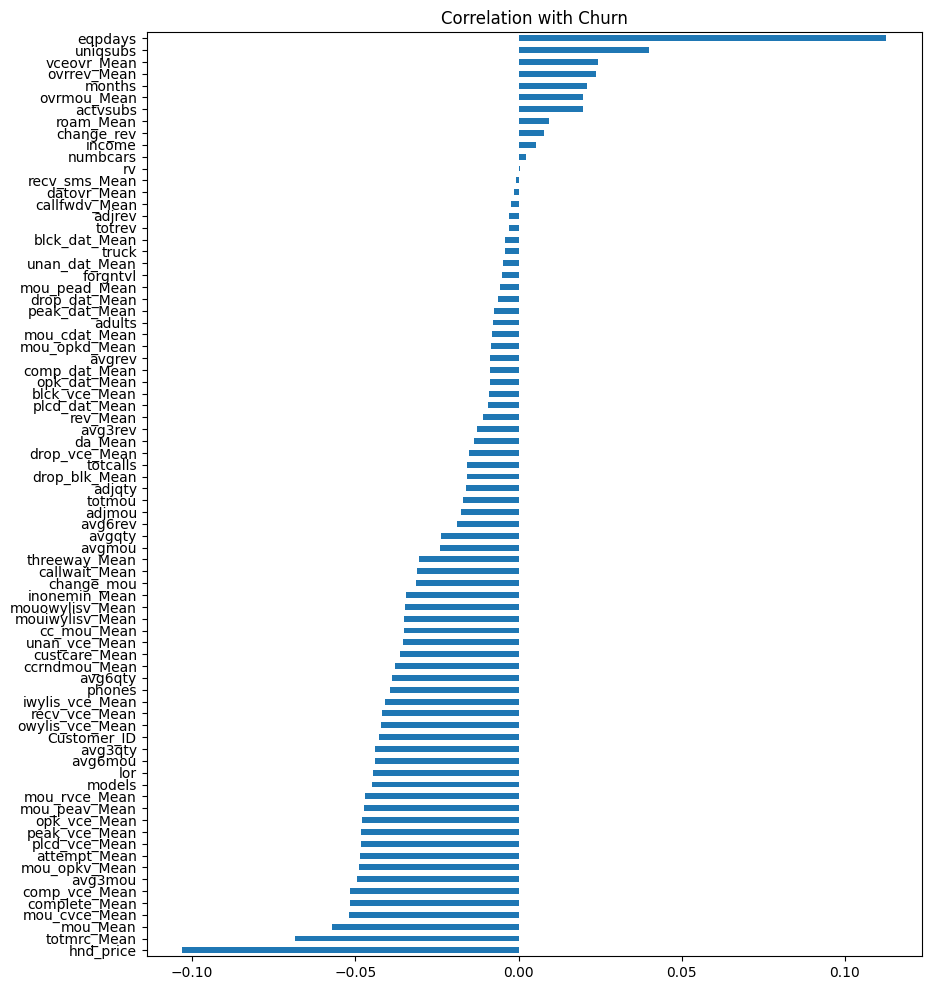

In [51]:
corr_with_churn = (
    customers_df.select_dtypes(include='number')
      .corr()['churn']
      .drop('churn')
      .sort_values()
)

plt.figure(figsize=(10,12))
corr_with_churn.plot(kind='barh')
plt.title('Correlation with Churn')
plt.show()

Device Age (eqpdays) vs Churn

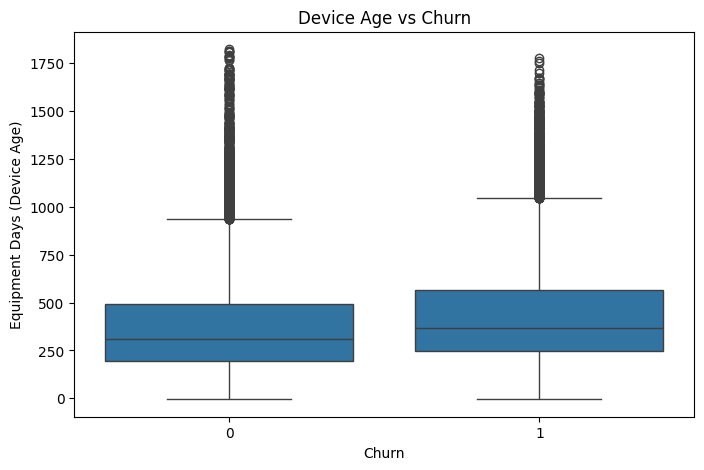

In [52]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='churn',
    y='eqpdays',
    data=customers_df
)

plt.title('Device Age vs Churn')
plt.xlabel('Churn')
plt.ylabel('Equipment Days (Device Age)')
plt.show()

Handset Price (hnd_price) vs Churn

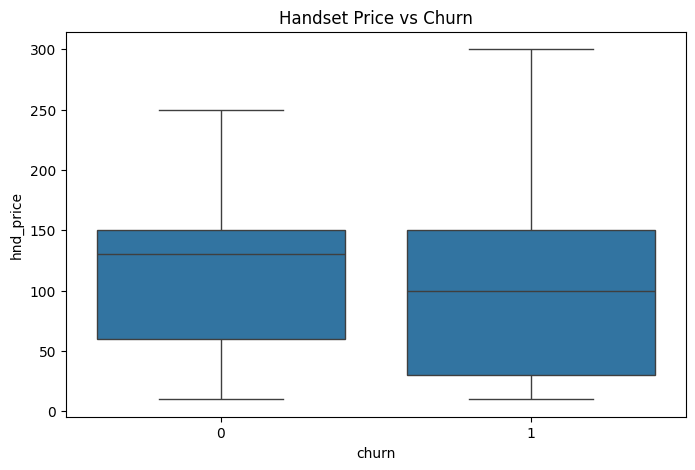

In [53]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='churn',
    y='hnd_price',
    data=customers_df,
    showfliers=False
)

plt.title('Handset Price vs Churn')
plt.show()

In [54]:
customers_df.groupby('churn')['eqpdays'].mean()

,eqpdays
churn,
0,363.280925
1,421.089524


Note: ---- from prev cell Customers using older devices are more likely to churn

In [55]:
customers_df.groupby('churn')['hnd_price'].mean()

,hnd_price
churn,
0,108.129344
1,95.539523


In [56]:
# customers_df['price_segment'] = pd.qcut(
#     customers_df['hnd_price'],
#     q=4,
#     labels=['Low','Medium','High','Premium']
# )

# pd.crosstab(
#     customers_df['price_segment'],
#     customers_df['churn'],
#     normalize='index'
# )

In [57]:
# price_churn = pd.crosstab(
#     customers_df['price_segment'],
#     customers_df['churn'],
#     normalize='index'
# )[1] * 100

# price_churn.plot(
#     kind='bar',
#     figsize=(8,5)
# )

# plt.title('Handset Price Segment vs Churn Rate')
# plt.ylabel('Churn Rate (%)')
# plt.xlabel('Price Segment')
# plt.ylim(0, 70)

# plt.tight_layout()
# plt.show()

# 4- PreProcessing

 4.1 Dropping Columns

In [58]:
X = customers_df.drop(['Customer_ID', 'churn'], axis=1)
Y =customers_df['churn']

In [59]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 98 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   uniqsubs          100000 non-null  int64  
 1   actvsubs          100000 non-null  int64  
 2   new_cell          100000 non-null  object 
 3   crclscod          100000 non-null  object 
 4   asl_flag          100000 non-null  object 
 5   totcalls          100000 non-null  int64  
 6   totmou            100000 non-null  float64
 7   totrev            100000 non-null  float64
 8   adjrev            100000 non-null  float64
 9   adjmou            100000 non-null  float64
 10  adjqty            100000 non-null  int64  
 11  avgrev            100000 non-null  float64
 12  avgmou            100000 non-null  float64
 13  avgqty            100000 non-null  float64
 14  avg3mou           100000 non-null  int64  
 15  avg3qty           100000 non-null  int64  
 16  avg3rev           100

4.1  split data to generate train and test dats set

80% Traing

20% Test

In [60]:


# X = features
# Y = target column ( Churn)

# Split data
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,      # 20% test data
    random_state=42,    # for reproducibility
    stratify=Y          # important for classification problems
)

4.3 Dealing Missing Values

what are numerical columns and Categorical columns

In [61]:

num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()  # Numerical coulmns
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist() # Categorical Columns

print("Numerical:", len(num_cols))
print("Categorical:", len(cat_cols))

Numerical: 77
Categorical: 21


Numerical by Medain
Categorical my Mode

In [62]:
# # Impute numerical columns using TRAIN median only
# for col in num_cols:
#     median_value = X_train[col].median()
#     X_train[col] = X_train[col].fillna(median_value)
#     X_test[col] = X_test[col].fillna(median_value)

#  Impute categorical columns
for col in cat_cols:
    X_train[col] = X_train[col].fillna("Unknown")
    X_test[col] = X_test[col].fillna("Unknown")

In [63]:
X_train.isnull().sum().sum()

np.int64(118305)

In [64]:
X_test.isnull().sum().sum()

np.int64(29264)

in next cell we should not see Object now after the previouse cell

In [65]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 98 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   uniqsubs          100000 non-null  int64  
 1   actvsubs          100000 non-null  int64  
 2   new_cell          100000 non-null  object 
 3   crclscod          100000 non-null  object 
 4   asl_flag          100000 non-null  object 
 5   totcalls          100000 non-null  int64  
 6   totmou            100000 non-null  float64
 7   totrev            100000 non-null  float64
 8   adjrev            100000 non-null  float64
 9   adjmou            100000 non-null  float64
 10  adjqty            100000 non-null  int64  
 11  avgrev            100000 non-null  float64
 12  avgmou            100000 non-null  float64
 13  avgqty            100000 non-null  float64
 14  avg3mou           100000 non-null  int64  
 15  avg3qty           100000 non-null  int64  
 16  avg3rev           100

Note from prev Cell ,Customers with lower-priced handsets are more likely to churn

#5. Basle Model

In [66]:
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np



cat_features = [
    X_train.columns.get_loc(col)
    for col in cat_cols
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train, Y_train)):
    print(f"Fold {fold + 1}")

    X_tr = X_train.iloc[train_idx].copy()
    X_val = X_train.iloc[valid_idx].copy()
    y_tr = Y_train.iloc[train_idx]
    y_val = Y_train.iloc[valid_idx]

    # Fill categorical missing values inside each fold
    for col in cat_cols:
        X_tr[col] = X_tr[col].fillna("Unknown").astype(str)
        X_val[col] = X_val[col].fillna("Unknown").astype(str)

    model = CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42,
        verbose=0
    )

    model.fit(
        X_tr,
        y_tr,
        cat_features=cat_features
    )

    y_val_prob = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_val_prob)

    cv_scores.append(auc)
    print("AUC:", round(auc, 4))

print("\nCV AUC Scores:", cv_scores)
print("Mean CV AUC:", round(np.mean(cv_scores), 4))

Fold 1
AUC: 0.6868
Fold 2
AUC: 0.6855
Fold 3
AUC: 0.681
Fold 4
AUC: 0.6933
Fold 5
AUC: 0.6914

CV AUC Scores: [np.float64(0.6867640960011), np.float64(0.6855058902947256), np.float64(0.6810179373108253), np.float64(0.6932530303101331), np.float64(0.691380480693053)]
Mean CV AUC: 0.6876


In [67]:
print(X.columns.tolist())

['uniqsubs', 'actvsubs', 'new_cell', 'crclscod', 'asl_flag', 'totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty', 'avg3mou', 'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty', 'avg6rev', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_price', 'phones', 'models', 'hnd_webcap', 'truck', 'rv', 'ownrent', 'lor', 'dwlltype', 'marital', 'adults', 'infobase', 'income', 'numbcars', 'HHstatin', 'dwllsize', 'forgntvl', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd', 'eqpdays', 'rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'drop_dat_Mean', 'blck_vce_Mean', 'blck_dat_Mean', 'unan_vce_Mean', 'unan_dat_Mean', 'plcd_vce_Mean', 'plcd_dat_Mean', 'recv_vce_Mean', 'recv_sms_Mean', 'comp_vce_Mean', 'comp_dat_Mean', 'custcare_Mean', 'ccrndmou_Mean', 'cc_mou_Mean', 'inonemin_Mean', 'threeway_Mean', 'mou_cvce_Mean', '

#Test AUC with final Model

In [68]:
final_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=42,
    verbose=0
)

final_model.fit(
    X_train,
    Y_train,
    cat_features=cat_features
)

y_pred_prob = final_model.predict_proba(X_test)[:,1]

from sklearn.metrics import roc_auc_score

print("Test AUC:", roc_auc_score(Y_test, y_pred_prob))

Test AUC: 0.6891445273521981


#Important features from final model

In [69]:
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': final_model.get_feature_importance()
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
97,months,15.093416
48,eqpdays,11.064462
58,change_mou,7.871825
50,mou_Mean,7.207991
51,totmrc_Mean,4.887052
13,avgqty,3.177991
59,change_rev,2.922103
24,hnd_price,2.775682
0,uniqsubs,2.288596
3,crclscod,2.241881


AUC : 0.6873

#6. Hypotheses & Feature Engineering

Find most important features after training , to start feature engineering

In [70]:
X_train["rev_per_min"] = (
    X_train["rev_Mean"] /
    (X_train["mou_Mean"] + 1)
)

X_test["rev_per_min"] = (
    X_test["rev_Mean"] /
    (X_test["mou_Mean"] + 1)
)

after adding this feature AUC =  0.6876 increased:

In [71]:
X_train["rev_ratio"] = (
    X_train["change_rev"] /
    (X_train["rev_Mean"] + 1)
)

X_test["rev_ratio"] = (
    X_test["change_rev"] /
    (X_test["rev_Mean"] + 1)
)

after adding this feature AUC =  0.6908 increased
:
---



In [72]:
# X_train["device_age_ratio"] = (
#     X_train["eqpdays"] /
#     (X_train["months"] + 1)
# )

# X_test["device_age_ratio"] = (
#     X_test["eqpdays"] /
#     (X_test["months"] + 1)
# )

after adding this feature AUC =0.6907 # decreased

In [73]:
X_train["mou_ratio"] = (
    X_train["change_mou"] /
    (X_train["mou_Mean"] + 1)
)

X_test["mou_ratio"] = (
    X_test["change_mou"] /
    (X_test["mou_Mean"] + 1)
)

after adding this feature AUC =  0.6957 increased

In [74]:
X_train["eqp_years"] = X_train["eqpdays"] / 365

X_test["eqp_years"] = X_test["eqpdays"] / 365

after adding this feature AUC: 0.6958

In [75]:
X_train["overage_ratio"] = (
    X_train["ovrrev_Mean"] /
    (X_train["rev_Mean"] + 1)
)

X_test["overage_ratio"] = (
    X_test["ovrrev_Mean"] /
    (X_test["rev_Mean"] + 1)
)

after adding this feature AUC =  0.6964  decreased

In [76]:
X_train["revenue_per_month"] = (
    X_train["totmrc_Mean"] /
    (X_train["months"] + 1)
)

X_test["revenue_per_month"] = (
    X_test["totmrc_Mean"] /
    (X_test["months"] + 1)
)

In [77]:
cat_features = [
    X_train.columns.get_loc(col)
    for col in cat_cols
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train, Y_train)):
    print(f"Fold {fold + 1}")

    X_tr = X_train.iloc[train_idx].copy()
    X_val = X_train.iloc[valid_idx].copy()
    y_tr = Y_train.iloc[train_idx]
    y_val = Y_train.iloc[valid_idx]

    # Fill categorical missing values inside each fold
    for col in cat_cols:
        X_tr[col] = X_tr[col].fillna("Unknown").astype(str)
        X_val[col] = X_val[col].fillna("Unknown").astype(str)

    model = CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42,
        verbose=0
    )


    model.fit(
        X_tr,
        y_tr,
        cat_features=cat_features
    )

    y_val_prob = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_val_prob)

    cv_scores.append(auc)
    print("AUC:", round(auc, 4))

print("\nCV AUC Scores:", cv_scores)
print("Mean CV AUC:", round(np.mean(cv_scores), 4))

Fold 1
AUC: 0.6972
Fold 2
AUC: 0.6959
Fold 3
AUC: 0.6901
Fold 4
AUC: 0.7014
Fold 5
AUC: 0.698

CV AUC Scores: [np.float64(0.6972220060598389), np.float64(0.6958793563882235), np.float64(0.6900938509354623), np.float64(0.7014271248892494), np.float64(0.6980206922092471)]
Mean CV AUC: 0.6965


In [78]:
# Train final model

In [79]:
X_train_final = X_train.copy()
X_test_final = X_test.copy()

for col in cat_cols:
    X_train_final[col] = X_train_final[col].fillna("Unknown").astype(str)
    X_test_final[col] = X_test_final[col].fillna("Unknown").astype(str)

final_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=0
)

final_model.fit(
    X_train_final,
    Y_train,
    cat_features=cat_features
)

CatBoostClassifier(depth=6, eval_metric='AUC', iterations=300, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=0)

Predicet

In [80]:
Y_pred = final_model.predict(X_test_final)
Y_prob = final_model.predict_proba(X_test_final)[:, 1]

Evalaution Metrics

In [81]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
print("Test Accuracy:", accuracy_score(Y_test, Y_pred))
print("Test AUC:", roc_auc_score(Y_test, Y_prob))

print("\nClassification Report:")
print(classification_report(Y_test, Y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(Y_test, Y_pred))

Test Accuracy: 0.63695
Test AUC: 0.6952062167694266

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.63      0.64     10088
           1       0.63      0.65      0.64      9912

    accuracy                           0.64     20000
   macro avg       0.64      0.64      0.64     20000
weighted avg       0.64      0.64      0.64     20000


Confusion Matrix:
[[6327 3761]
 [3500 6412]]


In [82]:
print(X_train.select_dtypes(include='object').columns)

Index(['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area',
       'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype',
       'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2',
       'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd'],
      dtype='object')


In [83]:

print(X.select_dtypes(include='object').columns)

Index(['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area',
       'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype',
       'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2',
       'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd'],
      dtype='object')


In [84]:
cat_cols = X.select_dtypes(include='object').columns

print("Before:", len(cat_cols))

for col in cat_cols:
    X[col] = X[col].fillna('Unknown')
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))

print("After:", X.select_dtypes(include='object').columns)

Before: 21
After: Index([], dtype='object')


In [85]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [86]:
print(X_train[X_train.dtypes[X_train.dtypes == 'object'].index].head())

Empty DataFrame
Columns: []
Index: [39301, 51212, 6408, 57171, 89299]


In [87]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, Y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

Feature Importance

In [88]:
feature_importance = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(feature_importance.head(20))

eqpdays          0.034292
change_mou       0.026902
months           0.023782
change_rev       0.021608
mou_Mean         0.020858
totrev           0.019966
adjrev           0.019638
avgqty           0.019382
avgrev           0.019327
avgmou           0.018780
rev_Mean         0.018580
avg6mou          0.018050
totcalls         0.017989
adjmou           0.017850
avg3mou          0.017842
adjqty           0.017749
totmou           0.017658
mou_cvce_Mean    0.017252
mou_opkv_Mean    0.016996
mou_peav_Mean    0.016896
dtype: float64


أخيرًا اشتغل 👏👏

دي Feature Importance من Random Forest، يعني الموديل شايف إن أهم عوامل توقع الـ churn هي:

eqpdays
عمر الجهاز الحالي. ده أقوى عامل.
change_mou
التغير في دقائق الاستخدام. لو الاستخدام بينخفض، العميل ممكن يسيب.
months
مدة بقاء العميل مع الشركة.
change_rev
التغير في الإيراد من العميل.
mou_Mean
متوسط دقائق الاستخدام.

الخلاصة المهمة للسلايد:

The model suggests that churn is mainly driven by device age, changes in usage behavior, customer tenure, and revenue/activity trends.

وده يقوي الـ proposal جدًا:

Target customers with old devices + declining usage + declining revenue before they churn.

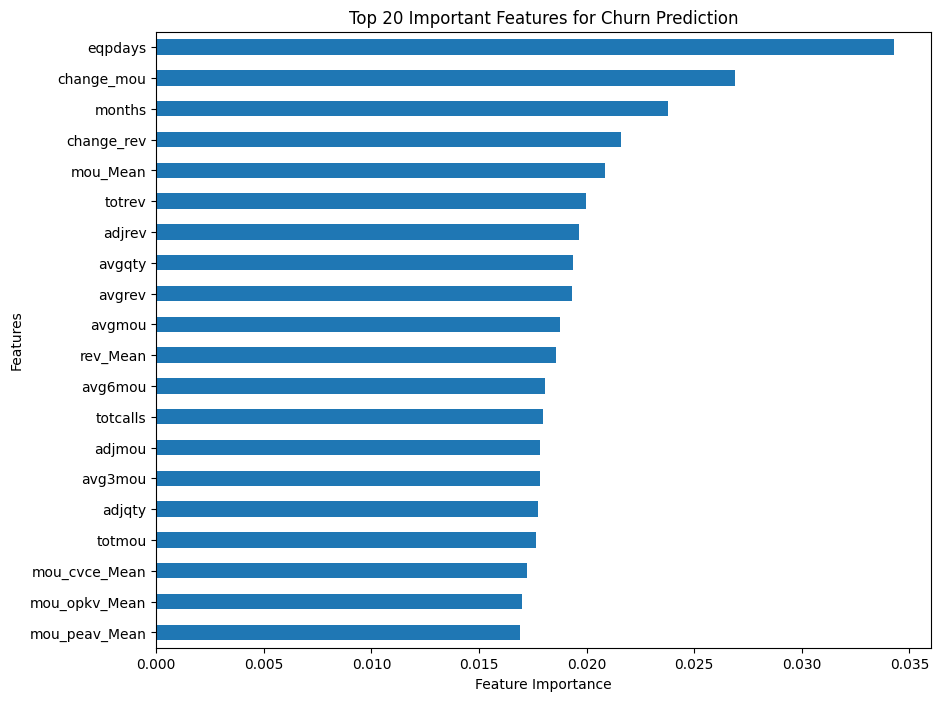

In [89]:
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))
top_features.sort_values().plot(kind='barh')
plt.title('Top 20 Important Features for Churn Prediction')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.show()

Customer Vlaue Score for new Calculations

In [90]:
customers_df["customer_value"] = (
    0.4 * customers_df["avgrev"] +
    0.4 * customers_df["totrev"] +
    0.2 * customers_df["months"]
)

In [91]:
customers_df["value_segment"] = pd.qcut(
    customers_df["customer_value"],
    q=4,
    labels=["Low","Medium","High","VIP"]
)

In [92]:
customers_df["value_segment"].value_counts()

,count
value_segment,
Medium,25001
Low,25000
VIP,25000
High,24999


Device Upgrade Opportunity

In [93]:
customers_df["old_device"] = customers_df["eqpdays"] > customers_df["eqpdays"].median()

In [94]:
pd.crosstab(
    customers_df["old_device"],
    customers_df["churn"],
    normalize="index"
)

churn,0,1
old_device,,
False,0.562115,0.437885
True,0.446169,0.553831


In [95]:
pd.crosstab(
    customers_df["value_segment"],
    customers_df["churn"],
    normalize="index"
)

churn,0,1
value_segment,,
Low,0.552960,0.447040
Medium,0.485221,0.514779
High,0.472979,0.527021
VIP,0.506360,0.493640


In [96]:
customers_df["declining_customer"] = (
    (customers_df["change_mou"] < 0) &
    (customers_df["change_rev"] < 0)
)

pd.crosstab(
    customers_df["declining_customer"],
    customers_df["churn"],
    normalize="index"
)

churn,0,1
declining_customer,,
False,0.519242,0.480758
True,0.482040,0.517960


In [97]:
customers_df["upgrade_target"] = (
    (customers_df["eqpdays"] > customers_df["eqpdays"].median()) &
    (customers_df["customer_value"] > customers_df["customer_value"].median())
)

pd.crosstab(
    customers_df["upgrade_target"],
    customers_df["churn"],
    normalize="index"
)

churn,0,1
upgrade_target,,
False,0.530070,0.469930
True,0.437168,0.562832


Multi-Line / Family Plan Opportunity

In [98]:
customers_df["inactive_lines"] = customers_df["uniqsubs"] - customers_df["actvsubs"]

customers_df["inactive_lines"].describe()

,inactive_lines
count,100000.000000
mean,0.189180
std,0.703161
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,143.000000


In [99]:
pd.crosstab(
    customers_df["inactive_lines"] > 0,
    customers_df["churn"],
    normalize="index"
)

churn,0,1
inactive_lines,,
False,0.514880,0.485120
True,0.439754,0.560246


In [100]:
(customers_df["inactive_lines"] > 0).value_counts(normalize=True) * 100

,proportion
inactive_lines,
False,86.024
True,13.976


High Revenue Decline Alert

In [101]:
customers_df["revenue_decline"] = customers_df["change_rev"] < 0

pd.crosstab(
    customers_df["revenue_decline"],
    customers_df["churn"],
    normalize="index"
)

churn,0,1
revenue_decline,,
False,0.502144,0.497856
True,0.506126,0.493874


New vs Long-Term Customers



In [102]:
customers_df["long_term"] = customers_df["months"] > customers_df["months"].median()

pd.crosstab(
    customers_df["long_term"],
    customers_df["churn"],
    normalize="index"
)

churn,0,1
long_term,,
False,0.509435,0.490565
True,0.499309,0.500691


VIP Risk List

In [103]:
customers_df["vip_at_risk"] = (
    (customers_df["customer_value"] > customers_df["customer_value"].quantile(0.75)) &
    (customers_df["eqpdays"] > customers_df["eqpdays"].median())
)

In [104]:
pd.crosstab(
    customers_df["vip_at_risk"],
    customers_df["churn"],
    normalize="index"
)

churn,0,1
vip_at_risk,,
False,0.513377,0.486623
True,0.443285,0.556715


To generate presenation table

In [105]:
final_model.feature_names_

['uniqsubs',
 'actvsubs',
 'new_cell',
 'crclscod',
 'asl_flag',
 'totcalls',
 'totmou',
 'totrev',
 'adjrev',
 'adjmou',
 'adjqty',
 'avgrev',
 'avgmou',
 'avgqty',
 'avg3mou',
 'avg3qty',
 'avg3rev',
 'avg6mou',
 'avg6qty',
 'avg6rev',
 'prizm_social_one',
 'area',
 'dualband',
 'refurb_new',
 'hnd_price',
 'phones',
 'models',
 'hnd_webcap',
 'truck',
 'rv',
 'ownrent',
 'lor',
 'dwlltype',
 'marital',
 'adults',
 'infobase',
 'income',
 'numbcars',
 'HHstatin',
 'dwllsize',
 'forgntvl',
 'ethnic',
 'kid0_2',
 'kid3_5',
 'kid6_10',
 'kid11_15',
 'kid16_17',
 'creditcd',
 'eqpdays',
 'rev_Mean',
 'mou_Mean',
 'totmrc_Mean',
 'da_Mean',
 'ovrmou_Mean',
 'ovrrev_Mean',
 'vceovr_Mean',
 'datovr_Mean',
 'roam_Mean',
 'change_mou',
 'change_rev',
 'drop_vce_Mean',
 'drop_dat_Mean',
 'blck_vce_Mean',
 'blck_dat_Mean',
 'unan_vce_Mean',
 'unan_dat_Mean',
 'plcd_vce_Mean',
 'plcd_dat_Mean',
 'recv_vce_Mean',
 'recv_sms_Mean',
 'comp_vce_Mean',
 'comp_dat_Mean',
 'custcare_Mean',
 'ccrndmou_M

In [106]:
X_test_for_pred = X_test.copy()

X_test_for_pred["rev_per_min"] = (
    X_test_for_pred["rev_Mean"] / (X_test_for_pred["mou_Mean"] + 1)
)

X_test_for_pred["rev_ratio"] = (
    X_test_for_pred["change_rev"] / (X_test_for_pred["rev_Mean"] + 1)
)

X_test_for_pred["mou_ratio"] = (
    X_test_for_pred["change_mou"] / (X_test_for_pred["mou_Mean"] + 1)
)

X_test_for_pred["eqp_years"] = (
    X_test_for_pred["eqpdays"] / 365
)

X_test_for_pred["overage_ratio"] = (
    X_test_for_pred["ovrrev_Mean"] / (X_test_for_pred["rev_Mean"] + 1)
)
X_test_for_pred["revenue_per_month"] = (
    X_test_for_pred["totrev"] / (X_test_for_pred["months"] + 1)
)

In [107]:
y_proba = final_model.predict_proba(X_test_for_pred)[:, 1]

output_example = pd.DataFrame({
    "Customer_ID": customers_df.loc[X_test_for_pred.index, "Customer_ID"],
    "Actual_Churn": Y_test.values,
    "Predicted_Churn_Risk": y_proba
})

output_example.head()

,Customer_ID,Actual_Churn,Predicted_Churn_Risk
72528,1072529,1,0.683581
61418,1061419,0,0.752294
76571,1076572,0,0.288268
23239,1023240,1,0.549695
94364,1094365,0,0.428478


In [108]:
high = output_example.nlargest(2, "Predicted_Churn_Risk")
low = output_example.nsmallest(2, "Predicted_Churn_Risk")

pd.concat([high, low])

,Customer_ID,Actual_Churn,Predicted_Churn_Risk
57207,1057208,1,0.965702
11694,1011695,1,0.956722
94818,1094819,0,0.160569
97751,1097752,0,0.172840
